# Execution audit — synthetic

SYNTHETIC TEST DATA ONLY. This is not a CICIDS2017 experiment and its scores must not be used in the dissertation.

Original code-cell sources are unchanged. Cell numbers in the report refer to the supplied notebook.

## 1. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Visual style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Path to dataset (update if your file is located elsewhere)
DATA_PATH = r"C:\Users\admin\Downloads\cicids2017_cleaned.csv"


## 2. Load Dataset

In [2]:
df = pd.read_csv(DATA_PATH)

# Strip any stray leading/trailing whitespace from column names
df.columns = df.columns.str.strip()

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Dataset shape: 2,416 rows x 53 columns


,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,PSH Flag Count,ACK Flag Count,Average Packet Size,Subflow Fwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Max,Active Min,Idle Mean,Idle Max,Idle Min,Attack Type
0,39.157894,45.661726,48.100451,59.999933,159.406086,54.353949,71.446738,53.396447,126.955305,84.087447,43.307460,34.456120,52.264254,49.073900,52.698174,10.997832,53.583824,105.551168,43.884776,44.182243,49.556945,38.491526,75.215477,46.416361,38.899308,19.589054,48.740108,48.447737,101.768703,59.570046,43.066634,17.831385,64.791293,53.108633,10.942122,43.064494,46.492769,44.726973,58.790376,36.736110,61.567393,62.349638,46.602854,57.781611,40.572994,56.763584,38.477691,47.980643,102.316216,71.584157,43.131715,43.409887,Normal Traffic
1,68.433304,50.504409,50.521268,53.895172,34.718000,65.961845,43.303540,62.827879,83.952812,21.115880,69.317090,55.912943,65.791140,46.414988,67.405723,50.107889,40.866694,59.583914,91.649693,43.670908,85.469349,44.619476,92.751893,48.750977,58.312491,37.022146,44.181204,22.140565,52.917297,36.076063,38.437144,26.699391,38.806728,59.971002,54.689152,70.309265,54.102528,47.931045,43.924118,55.563194,42.848005,47.008820,56.759169,39.481050,49.745809,37.979280,8.353416,45.893576,87.040040,33.331681,55.358602,36.575894,Normal Traffic
2,81.065335,48.277987,50.437128,31.276118,83.608075,8.542224,81.813847,46.552437,19.315806,25.289317,34.424471,54.267654,84.420928,45.043332,72.371731,3.454928,51.563492,27.054160,77.357389,43.640926,173.256849,44.253436,42.691211,52.564577,45.926675,38.328675,62.953585,127.504098,55.377938,59.520736,28.544814,33.153485,38.826544,59.037551,32.520925,96.904664,54.730696,16.705373,42.583045,20.571699,46.341583,32.961741,48.296007,57.884819,46.384323,58.133240,54.326043,54.413903,9.899923,47.712882,46.341552,73.195242,Normal Traffic
3,42.564763,47.348900,33.215679,58.400216,28.760783,55.347345,34.255645,33.473419,78.020362,72.418113,71.872554,39.327447,44.568210,50.163274,46.456105,59.603187,35.606718,55.820973,58.931212,50.221277,57.913195,44.359343,33.776407,52.860336,56.376773,15.314495,36.433080,23.326595,37.835105,52.991754,43.512002,25.542037,62.463139,49.899356,51.530296,60.540110,40.347319,71.112714,25.552038,28.401593,62.597521,43.045538,53.321592,44.746778,66.503136,79.683167,40.332064,50.206894,59.465911,47.222546,59.009327,28.026753,Normal Traffic
4,18.266402,55.693552,74.509135,32.521416,19.493177,68.024680,46.209630,55.001779,3.700634,87.295350,65.453249,70.048062,62.788001,45.015377,60.970351,85.993104,59.194868,25.478657,29.045815,32.495117,27.225221,43.273465,46.106768,47.117228,51.584594,101.860206,63.562851,4.125430,59.889371,29.706608,23.192509,94.258549,54.312412,28.357785,66.663451,48.727958,63.740779,86.252114,44.480487,74.231913,34.819068,50.092956,64.715564,39.120856,39.032536,101.496551,89.667238,53.297865,48.360167,32.250034,53.509219,27.011492,DoS


## 3. Initial Data Exploration

In [3]:
# Column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2416 entries, 0 to 2415
Data columns (total 53 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Destination Port             2416 non-null   float64
 1   Flow Duration                2416 non-null   float64
 2   Total Fwd Packets            2416 non-null   float64
 3   Total Length of Fwd Packets  2416 non-null   float64
 4   Fwd Packet Length Max        2416 non-null   float64
 5   Fwd Packet Length Min        2416 non-null   float64
 6   Fwd Packet Length Mean       2416 non-null   float64
 7   Fwd Packet Length Std        2416 non-null   float64
 8   Bwd Packet Length Max        2416 non-null   float64
 9   Bwd Packet Length Min        2416 non-null   float64
 10  Bwd Packet Length Mean       2416 non-null   float64
 11  Bwd Packet Length Std        2416 non-null   float64
 12  Flow Bytes/s                 2416 non-null   float64
 13  Flow Packets/s    

In [4]:
# Basic statistical summary of numeric features
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Destination Port,2416.0,50.317435,22.278383,0.089796,34.485999,49.619119,65.161961,135.481775
Flow Duration,2416.0,50.221257,9.983597,16.219594,43.637315,50.206705,57.135137,89.271661
Total Fwd Packets,2416.0,49.810188,9.999587,14.911235,43.300448,49.579441,56.674211,83.926641
Total Length of Fwd Packets,2416.0,49.796647,9.908069,16.707390,43.255330,49.831409,56.400587,80.757380
Fwd Packet Length Max,2416.0,58.996856,39.423216,0.025092,27.682635,53.014382,84.150452,229.421876
Fwd Packet Length Min,2416.0,50.482892,22.207886,0.160450,34.939352,49.781226,65.947620,125.249694
Fwd Packet Length Mean,2416.0,49.857875,21.381674,0.080811,34.683203,50.304412,64.496960,131.296575
Fwd Packet Length Std,2416.0,50.066612,10.257460,14.303061,43.264786,50.036044,56.743316,81.229799
Bwd Packet Length Max,2416.0,55.927708,36.779112,0.054581,25.673141,52.490910,81.302845,182.649859
Bwd Packet Length Min,2416.0,54.809992,32.191748,0.003729,29.179847,53.464837,78.410486,158.475202


In [5]:
# Check for missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
print(missing if not missing.empty else "None — dataset is already clean.")


Columns with missing values:
None — dataset is already clean.


In [6]:
# Check for infinite values (should already be handled, but verify)
inf_counts = np.isinf(df.select_dtypes(include=[np.number])).sum()
inf_counts = inf_counts[inf_counts > 0]
print("Columns with infinite values:")
print(inf_counts if not inf_counts.empty else "None — dataset is already clean.")


Columns with infinite values:
None — dataset is already clean.


In [7]:
# Check for duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")


Duplicate rows: 16


In [8]:
# Target column overview
print("Attack Type value counts:")
print(df["Attack Type"].value_counts())


Attack Type value counts:
Attack Type
Normal Traffic    1986
DoS                 72
DDoS                72
Port Scanning       72
Brute Force         72
Web Attacks         71
Bots                71
Name: count, dtype: int64


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class Distribution — Attack Type

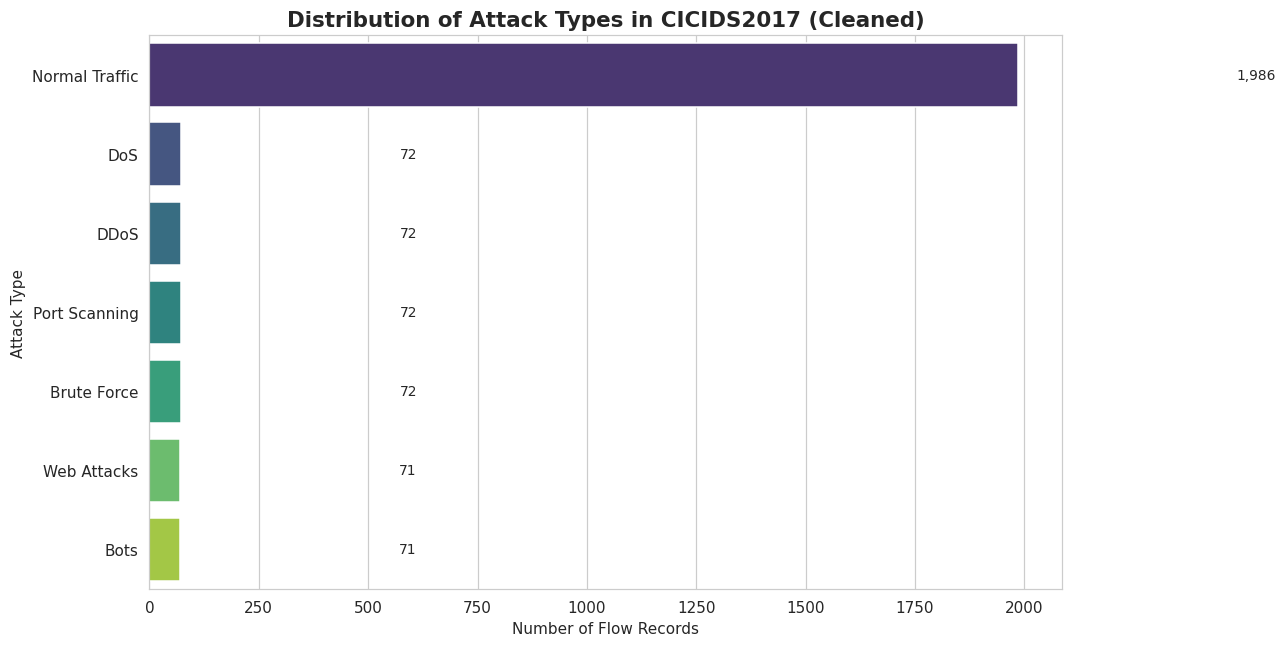


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



In [9]:
plt.figure(figsize=(12, 6))
order = df["Attack Type"].value_counts().index
ax = sns.countplot(data=df, y="Attack Type", order=order, palette="viridis")
ax.set_title("Distribution of Attack Types in CICIDS2017 (Cleaned)")
ax.set_xlabel("Number of Flow Records")
ax.set_ylabel("Attack Type")
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 500, p.get_y() + p.get_height()/2,
            f"{int(width):,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()


In [10]:
print(df["Attack Type"].unique())

['Normal Traffic' 'DoS' 'DDoS' 'Port Scanning' 'Brute Force' 'Web Attacks'
 'Bots']


### 4.2 Binary Reframing — Normal vs Abnormal

Binary Label
Normal      1986
Abnormal     430
Name: count, dtype: int64

Class imbalance ratio (Normal : Abnormal) = 4.62 : 1


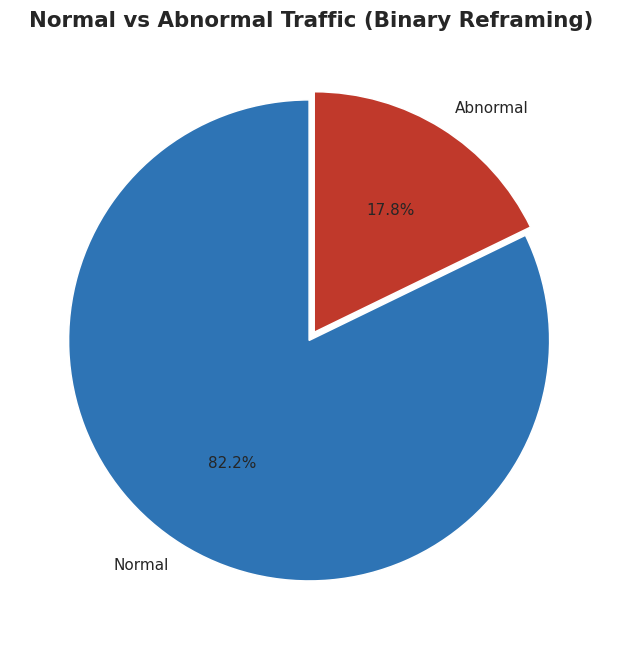

In [11]:
df["Binary Label"] = df["Attack Type"].apply(
    lambda x: "Normal" if x == "Normal Traffic" else "Abnormal"
)

counts = df["Binary Label"].value_counts()
print(counts)  # should show 2 rows: Normal and Abnormal

plt.figure(figsize=(6, 6))
colors = ["#2E74B5", "#C0392B"]
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", colors=colors,
        startangle=90, explode=(0.02, 0.02))
plt.title("Normal vs Abnormal Traffic (Binary Reframing)")
plt.tight_layout()
plt.show()

print(f"\nClass imbalance ratio (Normal : Abnormal) = "
      f"{counts['Normal'] / counts['Abnormal']:.2f} : 1")

### 4.3 Key Traffic Features by Class

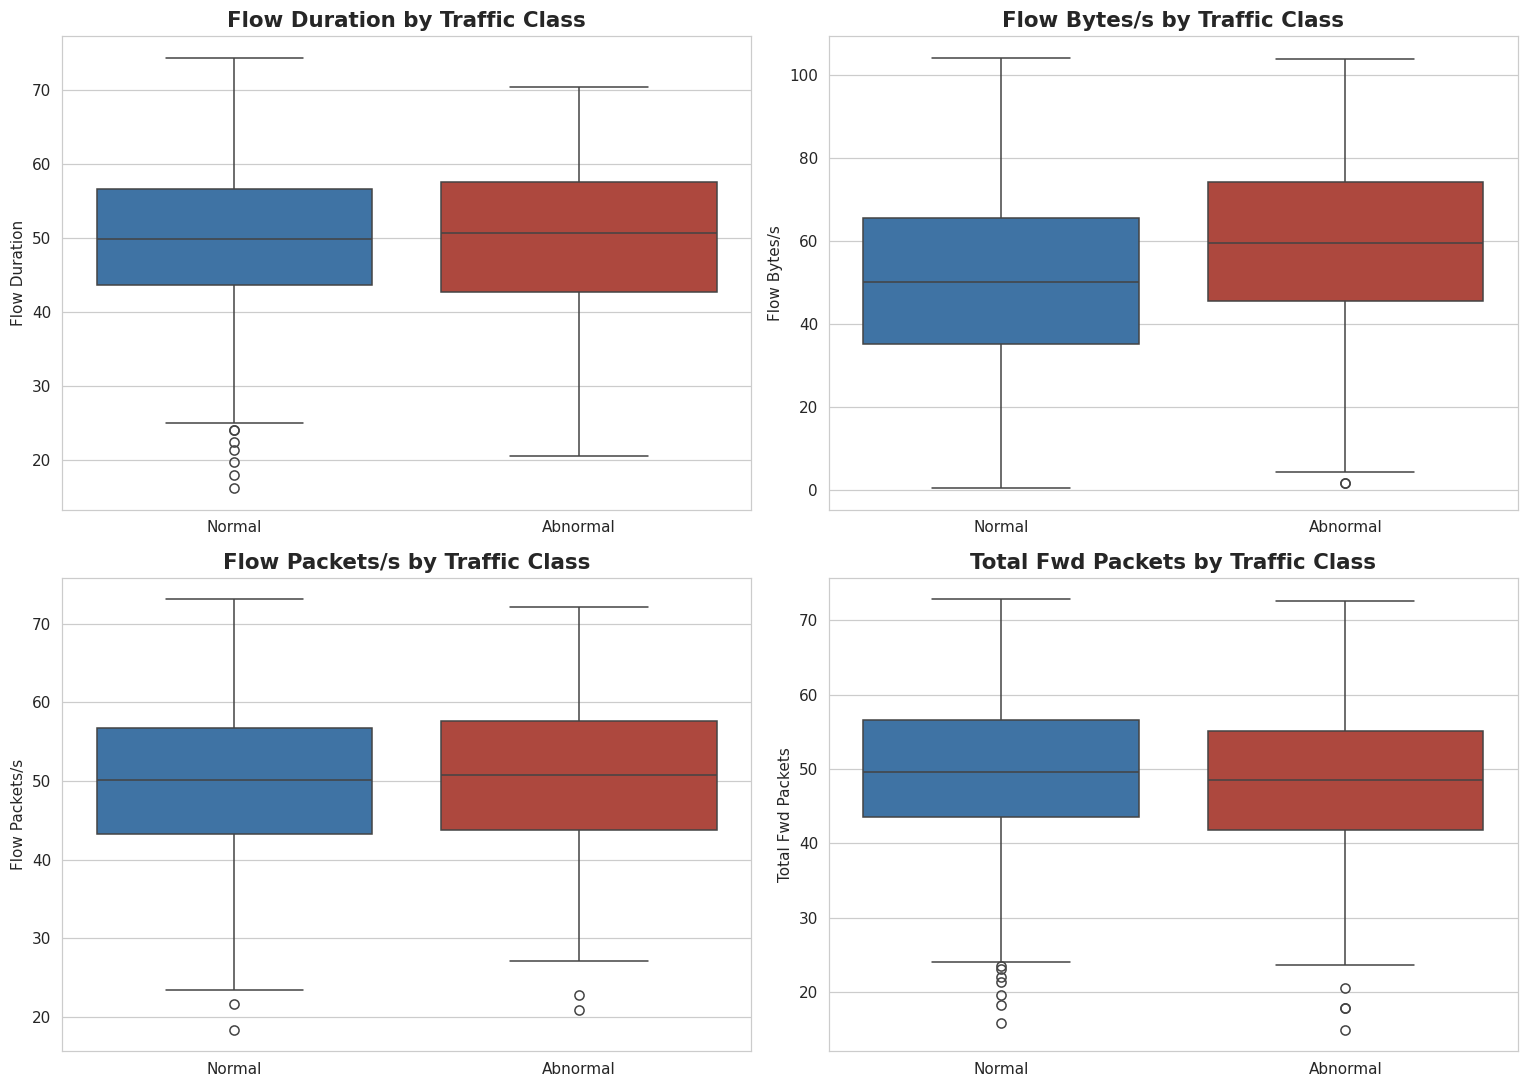


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



In [12]:
key_features = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Total Fwd Packets"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    # Clip extreme outliers at the 99th percentile purely for visualisation clarity
    upper = df[feature].quantile(0.99)
    plot_df = df[df[feature] <= upper]

    sns.boxplot(data=plot_df, x="Binary Label", y=feature, ax=axes[i],
                palette=["#2E74B5", "#C0392B"])
    axes[i].set_title(f"{feature} by Traffic Class")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()


### 4.4 Feature Correlation Heatmap

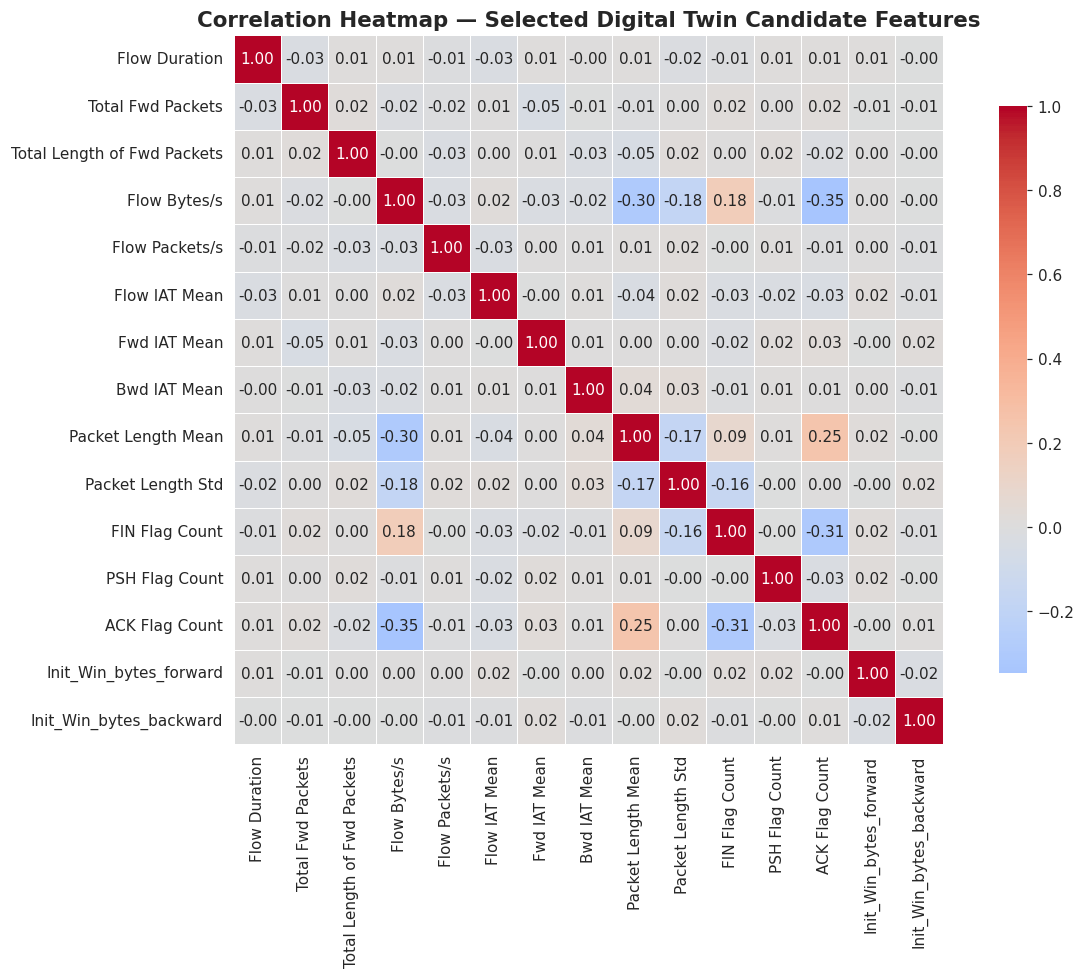

In [13]:
# Use a representative subset of numeric features to keep the heatmap readable
corr_features = [
    "Flow Duration", "Total Fwd Packets", "Total Length of Fwd Packets",
    "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "Fwd IAT Mean",
    "Bwd IAT Mean", "Packet Length Mean", "Packet Length Std",
    "FIN Flag Count", "PSH Flag Count", "ACK Flag Count",
    "Init_Win_bytes_forward", "Init_Win_bytes_backward"
]
corr_features = [f for f in corr_features if f in df.columns]

plt.figure(figsize=(12, 9))
corr_matrix = df[corr_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap — Selected Digital Twin Candidate Features")
plt.tight_layout()
plt.show()

### 4.5 Flow Duration Distribution — Normal vs Abnormal (Density Plot)

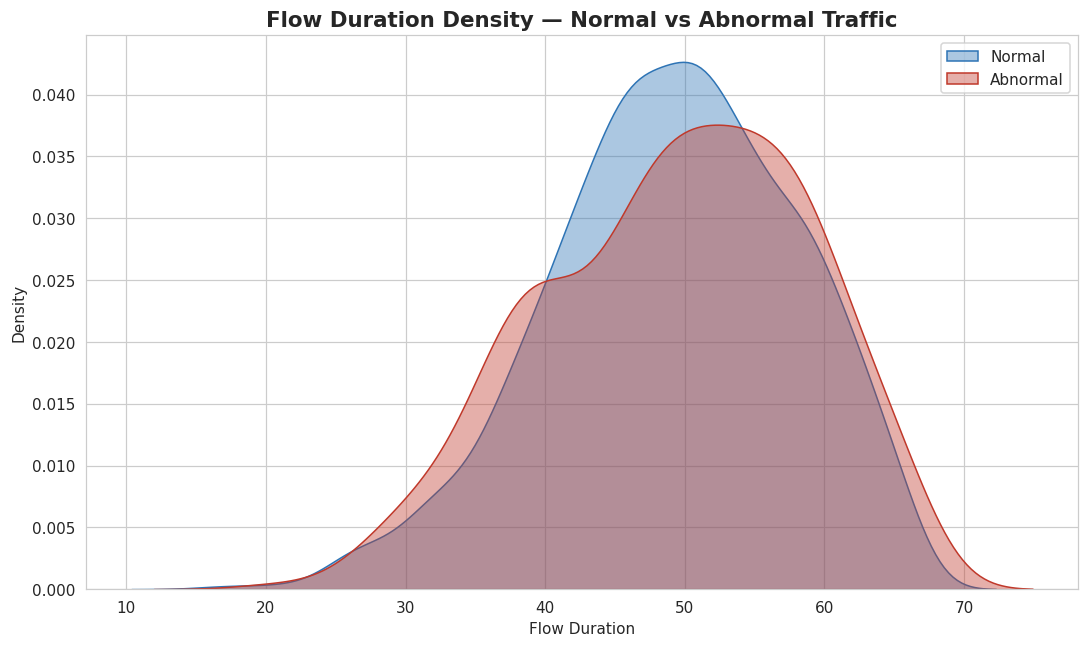

In [14]:
plt.figure(figsize=(10, 6))
upper = df["Flow Duration"].quantile(0.95)
plot_df = df[df["Flow Duration"] <= upper]

sns.kdeplot(data=plot_df[plot_df["Binary Label"] == "Normal"], x="Flow Duration",
            label="Normal", fill=True, alpha=0.4, color="#2E74B5")
sns.kdeplot(data=plot_df[plot_df["Binary Label"] == "Abnormal"], x="Flow Duration",
            label="Abnormal", fill=True, alpha=0.4, color="#C0392B")
plt.title("Flow Duration Density — Normal vs Abnormal Traffic")
plt.xlabel("Flow Duration")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Data Preprocessing

In [15]:
# Encode binary label: Normal = 0, Abnormal = 1 (Abnormal is the "positive"/alert class)
label_encoder = LabelEncoder()
df["Label_Encoded"] = label_encoder.fit_transform(df["Binary Label"])
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))


{'Abnormal': np.int64(0), 'Normal': np.int64(1)}


In [16]:
# Drop non-feature / leakage columns
drop_cols = ["Attack Type", "Binary Label", "Label_Encoded"]
X = df.drop(columns=drop_cols)
y = df["Label_Encoded"]

# Keep only numeric columns as features
X = X.select_dtypes(include=[np.number])

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")


Feature matrix shape: (2416, 52)
Target vector shape: (2416,)


In [17]:
# Train/test split — stratified to preserve class balance in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set:     {X_test.shape[0]:,} rows")


Training set: 1,812 rows
Test set:     604 rows


In [18]:
# Feature scaling (fit on training data only, to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 6. Digital Twin Representation Layer

In [19]:
class DigitalTwin:
    """
    A simplified software Digital Twin for TwinShield.

    Responsibility: receive raw network flow records and expose a reduced,
    security-relevant feature representation for the detection model —
    concentrating on traffic behaviour, communication activity, and
    network activity levels (proposal Section 5.3), rather than every
    raw feature available in the source data.
    """

    # Features the twin selects for behavioural monitoring
    TRACKED_FEATURES = [
        "Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Flow Packets/s",
        "Flow IAT Mean", "Fwd IAT Mean", "Bwd IAT Mean",
        "Packet Length Mean", "Packet Length Std",
        "FIN Flag Count", "PSH Flag Count", "ACK Flag Count",
        "Init_Win_bytes_forward", "Init_Win_bytes_backward"
    ]

    def __init__(self, feature_columns=None):
        self.feature_columns = feature_columns or self.TRACKED_FEATURES

    def represent(self, raw_flow_df: pd.DataFrame) -> pd.DataFrame:
        """Return the twin's tracked-feature representation of raw traffic."""
        available = [c for c in self.feature_columns if c in raw_flow_df.columns]
        return raw_flow_df[available].copy()


# Instantiate the Digital Twin and build its representation of the traffic
twin = DigitalTwin()
X_train_twin = twin.represent(X_train)
X_test_twin = twin.represent(X_test)

print(f"Digital Twin tracks {len(twin.feature_columns)} features:")
print(twin.feature_columns)


Digital Twin tracks 14 features:
['Flow Duration', 'Total Fwd Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Fwd IAT Mean', 'Bwd IAT Mean', 'Packet Length Mean', 'Packet Length Std', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward']


In [20]:
# Scale the twin's reduced feature representation (used by the TwinShield model below)
twin_scaler = StandardScaler()
X_train_twin_scaled = twin_scaler.fit_transform(X_train_twin)
X_test_twin_scaled = twin_scaler.transform(X_test_twin)


## 7. Baseline Detection Model

In [21]:
baseline_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline_model.fit(X_train_scaled, y_train)

y_pred_baseline = baseline_model.predict(X_test_scaled)
print("Baseline model trained on full feature set (no Digital Twin).")


Baseline model trained on full feature set (no Digital Twin).


## 8. TwinShield Detection Model (Random Forest)

In [22]:
twinshield_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"  # accounts for class imbalance seen in Section 4.2
)
twinshield_model.fit(X_train_twin_scaled, y_train)

y_pred_twinshield = twinshield_model.predict(X_test_twin_scaled)
y_proba_twinshield = twinshield_model.predict_proba(X_test_twin_scaled)[:, 1]

print("TwinShield model trained on Digital Twin's reduced feature representation.")


TwinShield model trained on Digital Twin's reduced feature representation.


## 9. Model Evaluation

In [23]:
def evaluate_model(y_true, y_pred, model_name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    fpr = fp / (fp + tn)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "False Positive Rate": fpr,
    }
    return metrics


baseline_metrics = evaluate_model(y_test, y_pred_baseline, "Baseline (Logistic Regression)")
twinshield_metrics = evaluate_model(y_test, y_pred_twinshield, "TwinShield (Random Forest + Digital Twin)")

results_df = pd.DataFrame([baseline_metrics, twinshield_metrics]).set_index("Model")
results_df.round(4)


,Accuracy,Precision,Recall,F1 Score,False Positive Rate
Model,,,,,
Baseline (Logistic Regression),0.8775,0.8996,0.9577,0.9277,0.4907
TwinShield (Random Forest + Digital Twin),0.8328,0.8399,0.9839,0.9062,0.8611


### 9.1 Confusion Matrices

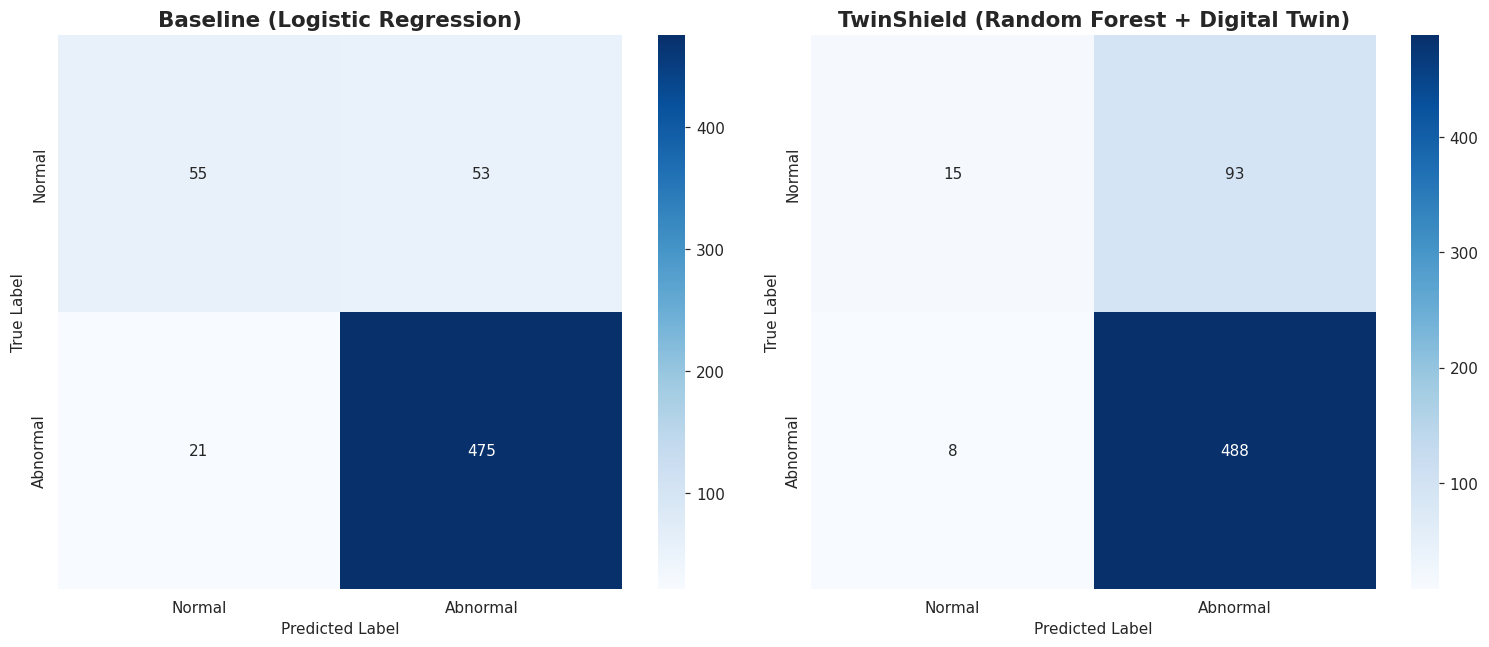

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, y_pred, title in zip(
    axes,
    [y_pred_baseline, y_pred_twinshield],
    ["Baseline (Logistic Regression)", "TwinShield (Random Forest + Digital Twin)"]
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Abnormal"],
                yticklabels=["Normal", "Abnormal"])
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()


### 9.2 Classification Report — TwinShield Model

In [25]:
print(classification_report(y_test, y_pred_twinshield,
                              target_names=["Normal", "Abnormal"]))


              precision    recall  f1-score   support

      Normal       0.65      0.14      0.23       108
    Abnormal       0.84      0.98      0.91       496

    accuracy                           0.83       604
   macro avg       0.75      0.56      0.57       604
weighted avg       0.81      0.83      0.79       604



### 9.3 ROC Curve — TwinShield Model

Baseline AUC:   0.9038
TwinShield AUC: 0.8251
AUC improvement: -0.0787


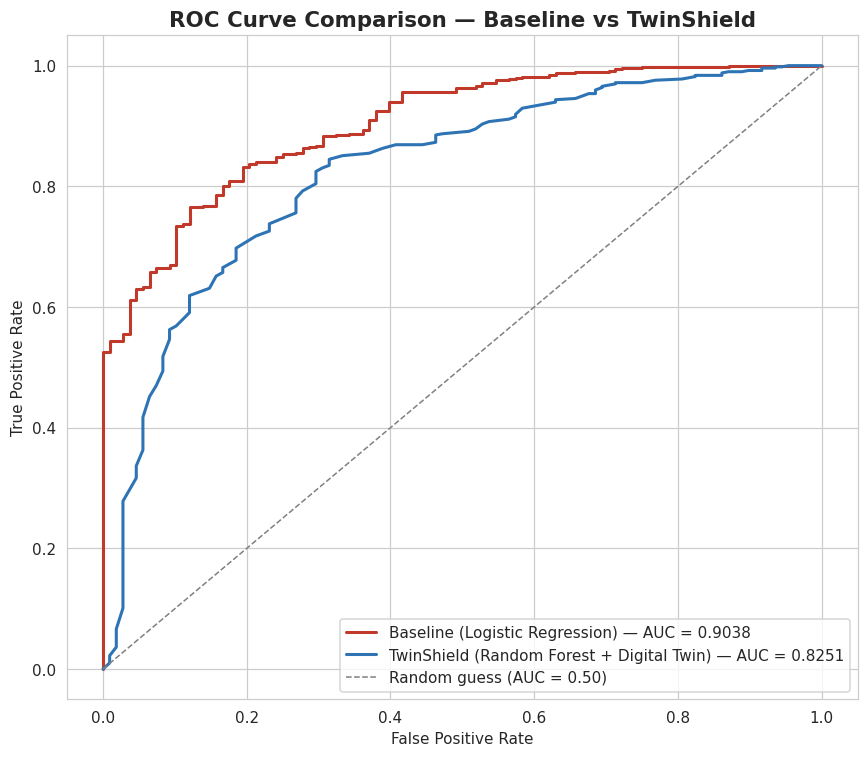

In [26]:
# Baseline probabilities (needed for ROC comparison — predict() alone isn't enough)
y_proba_baseline = baseline_model.predict_proba(X_test_scaled)[:, 1]
# ROC curves for both models
fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_proba_baseline)
roc_auc_baseline = auc(fpr_baseline, tpr_baseline)

fpr_twinshield, tpr_twinshield, _ = roc_curve(y_test, y_proba_twinshield)
roc_auc_twinshield = auc(fpr_twinshield, tpr_twinshield)

plt.figure(figsize=(8, 7))

plt.plot(fpr_baseline, tpr_baseline, color="#C0392B", lw=2,
         label=f"Baseline (Logistic Regression) — AUC = {roc_auc_baseline:.4f}")
plt.plot(fpr_twinshield, tpr_twinshield, color="#2E74B5", lw=2,
         label=f"TwinShield (Random Forest + Digital Twin) — AUC = {roc_auc_twinshield:.4f}")
plt.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--", label="Random guess (AUC = 0.50)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — Baseline vs TwinShield")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Baseline AUC:   {roc_auc_baseline:.4f}")
print(f"TwinShield AUC: {roc_auc_twinshield:.4f}")
print(f"AUC improvement: {roc_auc_twinshield - roc_auc_baseline:+.4f}")

## 10. Baseline vs TwinShield Comparison

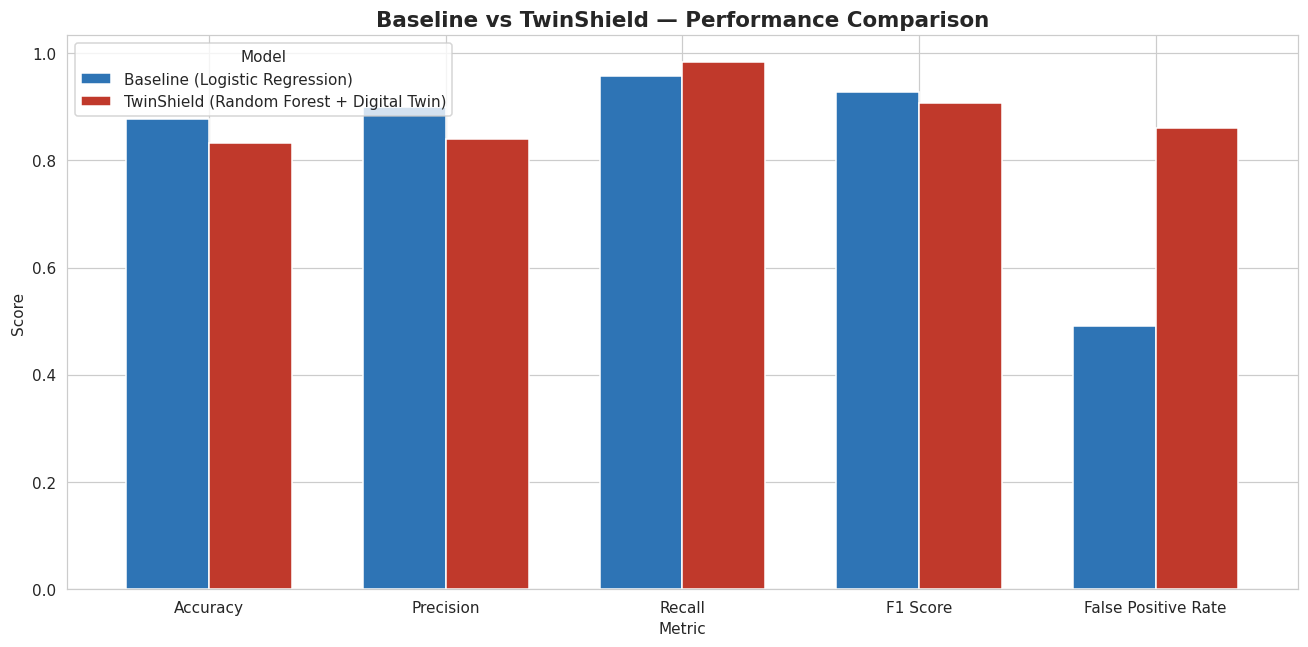

In [27]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "False Positive Rate"]
plot_df = results_df[metrics_to_plot].T

ax = plot_df.plot(kind="bar", figsize=(12, 6),
                   color=["#2E74B5", "#C0392B"], width=0.7)
ax.set_title("Baseline vs TwinShield — Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:
improvement = (results_df.loc["TwinShield (Random Forest + Digital Twin)"]
               - results_df.loc["Baseline (Logistic Regression)"])
print("Change in each metric — TwinShield relative to Baseline:")
print("(positive = improvement, except False Positive Rate where lower is better)\n")
print(improvement.round(4))


Change in each metric — TwinShield relative to Baseline:
(positive = improvement, except False Positive Rate where lower is better)

Accuracy              -0.0447
Precision             -0.0597
Recall                 0.0262
F1 Score              -0.0215
False Positive Rate    0.3704
dtype: float64


## 11. Feature Importance (TwinShield / Random Forest)

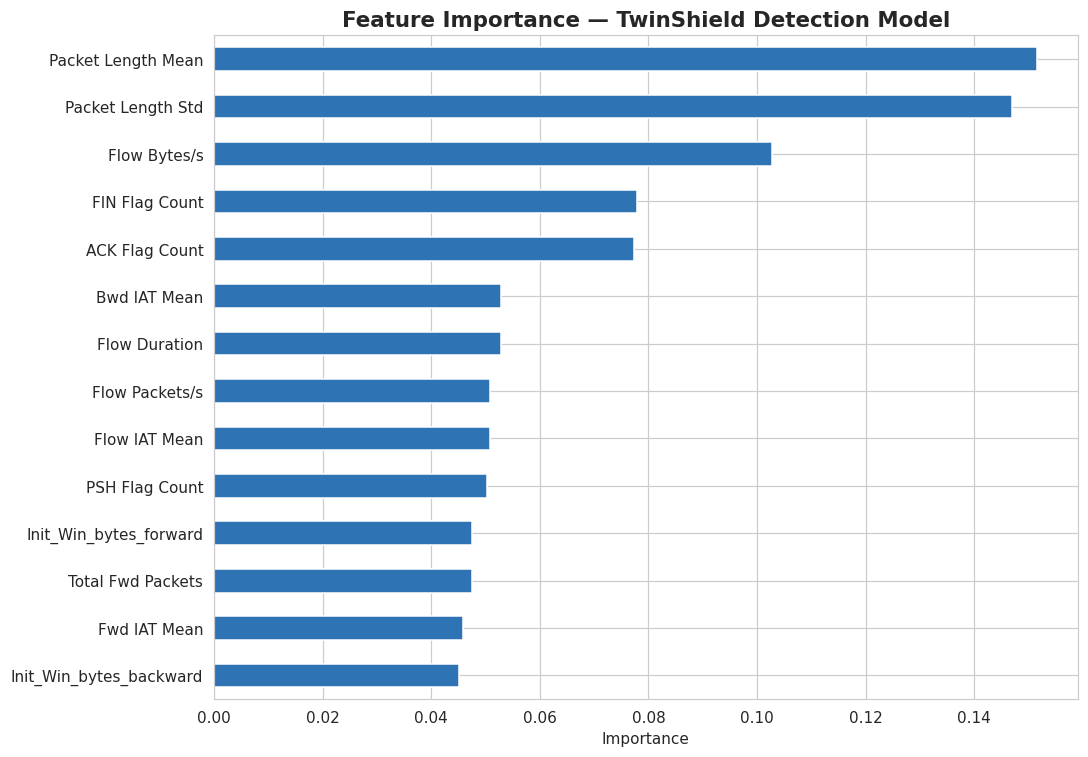

In [29]:
importances = pd.Series(
    twinshield_model.feature_importances_,
    index=twin.feature_columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
importances.plot(kind="barh", color="#2E74B5")
plt.title("Feature Importance — TwinShield Detection Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
